---
---

<h1><center><ins>Exercise Sheet 3</ins></center></h1>
<h2><center>Numerical Methods <br><br>

---
---

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from numpy import exp

## Exercise 1 - Root finding algorithms

**(A)** Implement the *bisection*, *secant*, *false position* and *Newton-Raphson* root finding methods, by coding your own version of these algorithms. Make sure to test your codes, checking that indeed they are able to find the root of a function (to do this, you can for example pick an analytic function that allows you to test the codes and for which you can compute the roots analytically).

**(B)** Use your implementation of the 4 root finding methods (from part **A**) to compute the root of the function:

$$f(x) = e^x - 1 - x - \frac{x^2}{2}$$

in the interval $x\in[-1,2]$. For each method, print out the position of the root and the number of iterations needed to reach it.

**(C)** Discuss your results, commenting how the methods compare to one another. Which one is the fastest/slowest? Why? What is the impact of the points you selected to start your iterations?

In [18]:
# Bisection method
def bisection(func, a, b, err=1e-5, n=0):
    # If either endpoint is already a root, return it immediately.
    if func(a) == 0:
        return a, n
    elif func(b) == 0:
        return b, n

    # The function must have opposite signs at the endpoints
    # to guarantee a root in the interval for a continuous function.
    elif func(a) * func(b) > 0:
        raise ValueError("Interval may contain multiple/no roots")

    else:
        # Calculate the midpoint of the current interval.
        x_m = (a + b) / 2

        # Stop if the midpoint is an exact root or the interval is
        # sufficiently small.
        if (func(x_m) == 0) or (abs(a - b) < err):
            return x_m, n

        # If the function changes sign between a and the midpoint,
        # the root lies in that half of the interval.
        elif func(x_m) * func(a) < 0:
            return bisection(func, a, x_m, err, n + 1)

        # Otherwise, if the function changes sign between b and
        # the midpoint, the root lies in that half.
        elif func(x_m) * func(b) < 0:
            return bisection(func, x_m, b, err, n + 1)


# Secant method
def secant(func, a, b, err=1e-5, n=0):
    # Check whether either initial guess is already a root.
    if func(a) == 0:
        return a, n
    elif func(b) == 0:
        return b, n

    # The secant formula divides by func(b) - func(a).
    # If the function values are equal, the denominator is zero.
    elif func(a) == func(b):
        raise ValueError("Denominator equals 0")

    else:
        # Find the x-intercept of the straight line through
        # the points (a, func(a)) and (b, func(b)).
        x_r = b - (func(b) / (func(b) - func(a))) * (b - a)

        # Stop if an exact root is found or the two current
        # approximations are sufficiently close.
        if (func(x_r) == 0) or (abs(x_r - b) < err):
            return x_r, n

        # Use the previous point b and the new approximation x_r
        # to construct the next secant line.
        else:
            return secant(func, b, x_r, err, n + 1)


# False-position method (Regula Falsi)
def false_position(func, a, b, err=1e-5, n=0):
    # Check whether either endpoint is already a root.
    if func(a) == 0:
        return a, n
    elif func(b) == 0:
        return b, n

    # The interpolation formula requires different function values.
    elif func(a) == func(b):
        raise ValueError("Denominator equals 0")

    # The endpoints must bracket a root by having opposite signs.
    elif func(a) * func(b) > 0:
        raise ValueError("Interval may contain multiple/no roots")

    else:
        # Calculate the x-intercept of the secant line through
        # (a, func(a)) and (b, func(b)).
        x_r = b - (func(b) / (func(b) - func(a))) * (b - a)

        # Stop if the function value is sufficiently close to zero
        # or if the interval width is below the tolerance.
        if (abs(func(x_r)) < err) or (abs(a - b) < err):
            return x_r, n

        # If func(a) and func(x_r) have opposite signs,
        # retain the interval [a, x_r].
        elif func(a) * func(x_r) < 0:
            return false_position(func, a, x_r, err, n + 1)

        # Otherwise, if func(b) and func(x_r) have opposite signs,
        # retain the interval [b, x_r].
        elif func(b) * func(x_r) < 0:
            return false_position(func, x_r, b, err, n + 1)


# Newton-Raphson method
def newton_raphson(func, dfunc, x, err=1e-5, h=1e-5, n=0):
    # If no derivative function is provided, approximate the
    # derivative numerically using a central difference.
    if dfunc == None:
        df = (func(x + h) - func(x - h)) / (2 * h)
    else:
        # Otherwise, evaluate the supplied derivative function.
        df = dfunc(x)

    # Newton-Raphson cannot proceed if the derivative is zero,
    # because the update formula would divide by zero.
    if df == 0:
        raise ValueError("Derivative equals 0")

    else:
        # Calculate the next approximation using the tangent line:
        # x_new = x - func(x) / func'(x).
        x_new = x - (func(x) / df)

        # Stop when two successive approximations differ
        # by less than the specified tolerance.
        if abs(x_new - x) < err:
            return x_new, n

        # Otherwise, repeat the method using the new approximation.
        else:
            return newton_raphson(func, dfunc, x_new, err, h, n + 1)


# Define the function whose roots we want to find.
# Its roots are x = -2, x = 1, and x = 3.
def test_function(x):
    return (x - 3) * (x + 2) * (x - 1)


# Apply the bisection method with the initial interval [0.6, 1.5].
root_bi, n_bi = bisection(test_function, 0.6, 1.5)

# Apply the secant method with initial guesses 0.5 and 1.5.
root_sec, n_sec = secant(test_function, 0.5, 1.5)

# Apply the false-position method with the initial interval [0.5, 1.5].
root_fp, n_fp = false_position(test_function, 0.5, 1.5)

# Apply Newton-Raphson starting from x = 1.6.
# Passing None means the derivative is calculated numerically.
root_nr, n_nr = newton_raphson(test_function, None, 1.6)


# Print the calculated root and the number of iterations for each method.
print(f"Bisection:\nRoot: {root_bi}, Iterations: {n_bi}\n")
print(f"Secant:\nRoot: {root_sec}, Iterations: {n_sec}\n")
print(f"False Position:\nRoot: {root_fp}, Iterations: {n_fp}\n")
print(f"Newton-Raphson:\nRoot: {root_nr}, Iterations: {n_nr}\n")    


Bisection:
Root: 1.0000019073486328, Iterations: 17

Secant:
Root: 0.999999999999572, Iterations: 4

False Position:
Root: 1.0000001219416823, Iterations: 4

Newton-Raphson:
Root: 0.9999999999986687, Iterations: 3



In [19]:
# Define the function whose roots we want to find.
# np.exp(x) represents e^x.
# The function is f(x) = e^x - 1 - x - x^2/2.
def b_function(x):
    return np.exp(x) - 1 - x - ((x**2) / 2)


# Find a root using the bisection method.
# The initial interval is [-1, 2].
# The method repeatedly halves the interval containing the root.
root_bi, n_bi = bisection(b_function, -1, 2)

# Find a root using the secant method.
# The initial guesses are x = -1 and x = 2.
# The method approximates the function using secant lines.
root_sec, n_sec = secant(b_function, -1, 2)

# Find a root using the false-position method.
# The initial interval is [-1, 2], which brackets a root
# because the function has opposite signs at the endpoints.
# Unlike bisection, this method uses linear interpolation
# to estimate the next root approximation.
root_fp, n_fp = false_position(b_function, -1, 2)

# Find a root using the Newton-Raphson method.
# The initial guess is x = 0.5.
# Passing None means that the derivative is approximated
# numerically using the central difference formula.
root_nr, n_nr = newton_raphson(b_function, None, 0.5)


# Print the approximated root and number of iterations
# for each of the four numerical methods.
print(f"Bisection:\nRoot: {root_bi}, Iterations: {n_bi}\n")
print(f"Secant:\nRoot: {root_sec}, Iterations: {n_sec}\n")
print(f"False Position:\nRoot: {root_fp}, Iterations: {n_fp}\n")
print(f"Newton-Raphson:\nRoot: {root_nr}, Iterations: {n_nr}\n")

Bisection:
Root: 7.62939453125e-06, Iterations: 16

Secant:
Root: -2.5977650494916025e-05, Iterations: 37

False Position:
Root: -0.039274473842066726, Iterations: 2273

Newton-Raphson:
Root: 1.485365994637032e-05, Iterations: 25



In this example, bisection is the most efficient and accurate, while false position is the slowest because one end of the interval never changes. Newton–Raphson and the secant method lie between these extremes. The results also demonstrate that convergence speed depends not only on the numerical method but on the function itself and the initial guesses.

## Exercise 2 - Sets of linear equations

Determine the solution to the following set of linear equations:

$$ 
\begin{cases}
5 x_1 + 3 x_2 &= 15 \\
x_1 - 4 x_2 &= -2 \ ,
\end{cases}
$$

where $x_1$ and $x_2$ are the variables of interest.

**(A)** Formulate the problem by using the matrix representation, as we saw in class, clearly defining the coefficient matrix and the vector of right-hand-side values.

**(B)** Using the appropriate built-in python functions, carry out the LU decomposition of the coefficient matrix, and print out the L and U matrices separately. Solve the set of equations and check that the solution is indeed valid.

**(C)** What is the solution to the following set of equations? 

$$ 
\begin{cases}
x_1 - 4 x_2 &= 3 \\
5 x_1 + 3 x_2 &= -7
\end{cases}
$$

Print out the solution, and motivate the steps you took to solve it.

In [20]:
# Import functions for LU decomposition and solving linear systems.
from scipy.linalg import lu, lu_factor, lu_solve


def solve_lin_eq(A, b):

    # Perform LU decomposition with pivoting.
    # P is the permutation matrix, L is the lower triangular matrix,
    # and U is the upper triangular matrix.
    # The decomposition satisfies A = P @ L @ U.
    p, l, u = lu(A)

    # Print the lower and upper triangular matrices.
    print(f"L: {l}")
    print(f"U: {u}")

    # Calculate the LU factorization of A for solving the system.
    # l_u stores L and U together in a single array.
    # piv stores the pivot indices used for row permutations.
    l_u, piv = lu_factor(A)

    # Solve the linear system A @ x = b using the LU factorization.
    # This is more efficient than explicitly calculating A's inverse.
    x = lu_solve((l_u, piv), b)

    # Print the calculated solution vector.
    print(f"Solution: {x}")

    # Check whether the calculated solution satisfies the original system.
    # A @ x - b should be approximately the zero vector.
    # np.allclose accounts for small floating-point rounding errors.
    if np.allclose(A @ x - b, np.array([0, 0])):
        print("Solution is valid\n")


# Define the coefficient matrix A_1 for the first linear system:
# 5*x_1 + 3*x_2  = 15
#   x_1 - 4*x_2  = -2
A_1 = np.array([[5, 3],
                [1, -4]])

# Define the right-hand-side vector b_1.
b_1 = np.array([15, -2])

# Solve the first linear system and print its results.
solve_lin_eq(A_1, b_1)


# Define the coefficient matrix A_2 for the second linear system:
#   x_1 - 4*x_2  =  3
# 5*x_1 + 3*x_2  = -7
A_2 = np.array([[1, -4],
                [5, 3]])

# Define the right-hand-side vector b_2.
b_2 = np.array([3, -7])

# Solve the second linear system and print its results.
solve_lin_eq(A_2, b_2)


L: [[1.  0. ]
 [0.2 1. ]]
U: [[ 5.   3. ]
 [ 0.  -4.6]]
Solution: [2.34782609 1.08695652]
Solution is valid

L: [[1.  0. ]
 [0.2 1. ]]
U: [[ 5.   3. ]
 [ 0.  -4.6]]
Solution: [-0.82608696 -0.95652174]
Solution is valid



## Exercise 3 - The Newton fractal

In the lecture, we discussed the Newton fractal. The aim of this exercise is to plot it. 

**(A)** Generate a complex plane of numbers between [-2,2] for the real and imaginary parts. You can use the function np.linspace for the Re and Im parts (assume a sufficient number of points, for instance, a few hundred), and then use np.meshgrid to create a full Re, Im grid. You create the complex numbers by using Z = X + 1j * Y. This is the initial set of complex points for your iteration.

**(B)** For every starting point in your grid that you generated in (A), run the Newton-Raphson iteration as $$z_{i+1} = z_{i} - \frac{z_{i}^3 - 1}{3 z_{n}^2} $$ Test how many times you need to run the iteration for the values to converge to one of the three roots (tip: several tens of iteration should be sufficient).

**(C)** Calculate analytically or look up online the three roots of the function $$f(z) = z^3 - 1$$ and store them. For each point you have obtained in (B), calculate the distance to every root using, for instance, np.abs. and determine the nearest root. 

**(D)** Plot the result. You can use the function plt.imshow or a similar solution. Assign the color to each plot according to the nearest root. Add the three roots using e.g. plt.scatter.

Number of iterations: 48


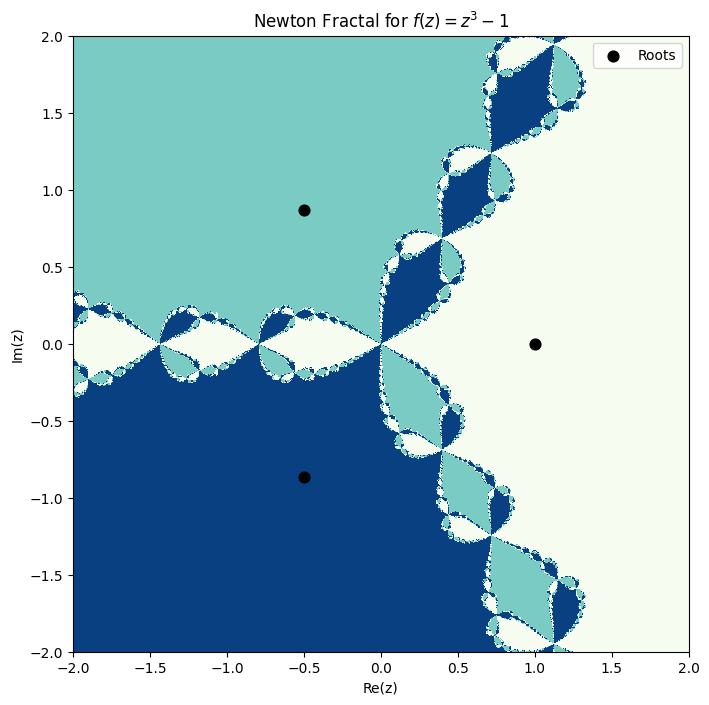

In [21]:
# Create 1000 evenly spaced values for the real and imaginary axes.
re = np.linspace(-2, 2, 1000)
im = np.linspace(-2, 2, 1000)

# Create two 2D arrays containing all combinations of real and imaginary
# coordinates. Each pair (x[i,j], y[i,j]) represents one point in the complex plane.
x, y = np.meshgrid(re, im)

# Combine the real and imaginary parts to create a 2D array of complex numbers.
# Each entry is z = x + i*y.
z = x + 1j * y


# Define the Newton-Raphson method for complex numbers.
# n is the maximum number of iterations.
# err is the tolerance used to decide whether a point has converged to a root.
def nr_frac(z, n, err=1e-14):

    # Make a copy so that the original array of complex numbers is not modified.
    z = z.copy()

    # Initialize the iteration counter.
    iterations = 0

    # Create a Boolean mask identifying points that still need iteration.
    # The first condition checks whether f(z) = z^3 - 1 is sufficiently
    # close to zero. The second condition excludes points close to z = 0,
    # where the Newton-Raphson formula would divide by zero.
    mask = (np.abs(z**3 - 1) >= err) & (np.abs(z) > err)

    # Perform at most n Newton-Raphson iterations.
    for i in range(1, n + 1):

        # Update the mask at the beginning of each iteration.
        # True means that the corresponding point still needs to be updated.
        mask = (np.abs(z**3 - 1) >= err) & (np.abs(z) > err)

        # If no points need updating anymore, stop the iteration early.
        if not np.any(mask):
            break

        # Apply the Newton-Raphson formula only to the points selected by
        # the mask, leaving already converged or excluded points unchanged.
        #
        # General formula:
        # z_new = z - f(z) / f'(z)
        #
        # Here, f(z) = z^3 - 1 and f'(z) = 3*z^2.
        z[mask] = z[mask] - (
            (z[mask]**3 - 1) / (3 * z[mask]**2)
        )

        # Store the index of the current iteration.
        iterations = i

    # Return the number of iterations performed and the final complex array.
    return iterations, z


# Apply the Newton-Raphson method to all points in the complex plane,
# allowing a maximum of 100 iterations per point.
iterations, z_new = nr_frac(z, 100)

# Print the number of iterations performed by the algorithm as a whole.
print(f"Number of iterations: {iterations}")


# Define the three exact roots of z^3 - 1 = 0.
# These are the three cube roots of unity, equally spaced around the unit circle.
roots = np.array([
    1 + 0j,
    -1/2 + 1j * np.sqrt(3)/2,
    -1/2 - 1j * np.sqrt(3)/2
])


# Calculate the distance of every final point to each of the three roots.
# np.abs(z_new - root) calculates the complex-plane distance.
# np.stack combines the three distance arrays into one 3D array.
diff = np.stack([np.abs(z_new - root) for root in roots])


# For each point in the complex plane, determine which root is closest.
# axis=0 means that we compare the distances to the three roots.
# The result is a 2D array:
#   0 -> closest to the first root
#   1 -> closest to the second root
#   2 -> closest to the third root
closest_root = np.argmin(diff, axis=0)


# Create a square figure for the Newton fractal.
plt.figure(figsize=(8, 8))

# Display the array of root assignments as an image.
# extent maps the array coordinates to the complex plane [-2, 2] x [-2, 2].
# origin="lower" places the negative imaginary values at the bottom.
# cmap="GnBu" selects the color map.
# interpolation="nearest" prevents smoothing between neighboring pixels.
plt.imshow(
    closest_root,
    extent=[-2, 2, -2, 2],
    origin="lower",
    cmap="GnBu",
    interpolation="nearest"
)

# Mark the exact roots with black circles.
plt.scatter(
    roots.real,
    roots.imag,
    color="black",
    marker="o",
    s=60,
    label="Roots"
)

# Label the real and imaginary axes.
plt.xlabel("Re(z)")
plt.ylabel("Im(z)")

# Add a title describing the function used to generate the fractal.
plt.title("Newton Fractal for $f(z)=z^3-1$")

# Display the legend and show the completed plot.
plt.legend()
plt.show()
